In [3]:
import sys
print(sys.executable)

/home/gmvaz/.conda/envs/horse_26/bin/python


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [5]:
import pandas as pd

untargeted_lipidomics_df = pd.read_excel("/home/gmvaz/Horse_Metabolomics_26/lipidomics_serum_urine_clean.xlsx", sheet_name = ["Urine data", "Serum data", "Urine internal standards", "Serum internal standards"])
targeted_met_lipids_serum_df = pd.read_excel("/home/gmvaz/Horse_Metabolomics_26/mx843346_serum_clean.xlsx", sheet_name = "Data")
targeted_met_lipids_urine_df = pd.read_excel("/home/gmvaz/Horse_Metabolomics_26/mx843346_urine_clean.xlsx", sheet_name = "Data")
untargeted_metabolomics_df = pd.read_excel("/home/gmvaz/Horse_Metabolomics_26/mx844156_clean.xlsx", sheet_name = "submit")

In [7]:
untargeted_lipidomics_df["Urine data"].head(10)

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Label,Frankie 1.29.2032,Spork 1.29.2024,Charlie 1.29.2029,S2207326,S2208680,S2209415,S2209728,S2301257,Spagurter 1.29.2030,Dan 1.29.2028,MtdBlank001,PoolQC001
0,NaN,NaN,NaN,NaN,NaN,NaN,Sample #,30,31,32,33,34,35,36,37,38,40,Blank,Pool
1,NaN,NaN,NaN,NaN,NaN,NaN,Species,equine,equine,equine,equine,equine,equine,equine,equine,equine,equine,NaN,equine
2,NaN,NaN,NaN,NaN,NaN,NaN,Organ,urine,Urine,Urine,Urine,Urine,Urine,Urine,Urine,Urine,Urine,NaN,urine
3,NaN,NaN,NaN,NaN,NaN,NaN,Treatment,control,control,control,Sudden death,Sudden death,Sudden death,Sudden death,Sudden death,control,control,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,Subtreatment,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,File ID,Knych0010_MX843469_posLIPIDS_Frankie-1-29-2024...,Knych0002_MX843469_posLIPIDS_Spork-1-29-2024-0...,Knych0007_MX843469_posLIPIDS_Charlie-1-29-2024...,Knych0003_MX843469_posLIPIDS_S2207326-033.raw,Knych0005_MX843469_posLIPIDS_S2208680-034.raw,Knych0001_MX843469_posLIPIDS_S2209415-035.raw,Knych0009_MX843469_posLIPIDS_S2209728-036.raw,Knych0004_MX843469_posLIPIDS_S2301257-037.raw,Knych0008_MX843469_posLIPIDS_Spagurter-1-29-20...,Knych0006_MX843469_posLIPIDS_Dan-1-29-2024-040...,MtdBlank001_MX843469_posLIPIDS_preKnych0001.raw,PoolQC001_MX843469_posLIPIDS_preKnych0001.raw
6,NaN,NaN,NaN,NaN,NaN,NaN,File ID,Knych0010_MX843469_negLIPIDS_Frankie-1-29-2024...,Knych0002_MX843469_negLIPIDS_Spork-1-29-2024-0...,Knych0007_MX843469_negLIPIDS_Charlie-1-29-2024...,Knych0003_MX843469_negLIPIDS_S2207326-033.raw,Knych0005_MX843469_negLIPIDS_S2208680-034.raw,Knych0001_MX843469_negLIPIDS_S2209415-035.raw,Knych0009_MX843469_negLIPIDS_S2209728-036.raw,Knych0004_MX843469_negLIPIDS_S2301257-037.raw,Knych0008_MX843469_negLIPIDS_Spagurter-1-29-20...,Knych0006_MX843469_negLIPIDS_Dan-1-29-2024-040...,MtdBlank001_MX843469_negLIPIDS_preKnych0001.raw,PoolQC001_MX843469_negLIPIDS_preKnych0001.raw
7,identifier,annotation,ion species,InChI Key,m/z,ret.time (min),ESI mode,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height,Peak Height
8,1.93_861.55,"1,2-Dioleoyl-sn-glycero-3-phospho-(1'-myo-inos...",[M-H]-,LALGUHSIWLNTNW-UHFFFAOYSA-N,861.5491,1.925,ESI neg,15834,8702,21875,1757058,950397,8775,3825044,21689,20278,221791,NaN,356981
9,0.26_319.23,12-HETE,[M-H]-,ZNHVWPKMFKADKW-LQWMCKPYSA-N,319.2277,0.261,ESI neg,24072,13738,3955,83528,874525,6655,974495,4214,7017,65054,2438,112108


## Untargeted Lipidomics

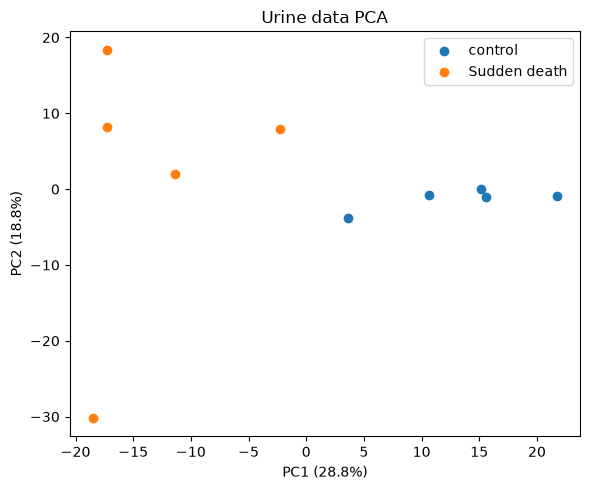

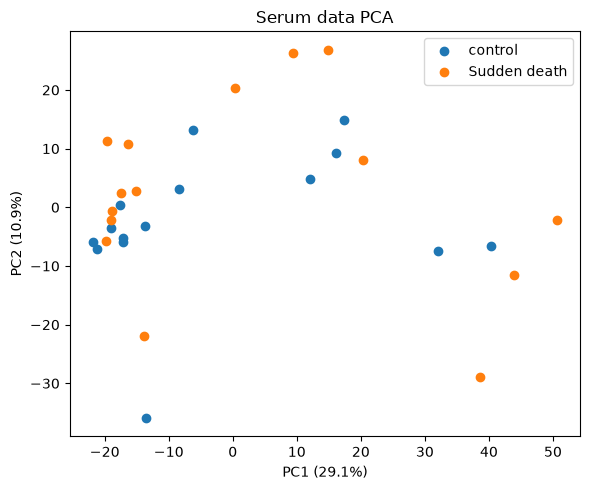

In [9]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

for sheet in ["Urine data", "Serum data"]:
    df = untargeted_lipidomics_df[sheet]

    # Select control and sudden death samples
    groups = df.iloc[3, 7:]
    keep = groups.isin(["control", "Sudden death"])
    groups = groups[keep].to_numpy()

    # Extract peak heights (samples x lipids)
    X = df.iloc[8:, 7:].loc[:, keep]
    X = X.apply(pd.to_numeric, errors="coerce").T

    # Preprocess
    X = X.loc[:, X.notna().mean() >= 0.8]
    X = X.fillna(X.median())
    X = StandardScaler().fit_transform(np.log1p(X))

    # PCA
    pca = PCA(n_components=2)
    scores = pca.fit_transform(X)

    # Plot
    plt.figure(figsize=(6, 5))

    for group in ["control", "Sudden death"]:
        mask = groups == group
        plt.scatter(scores[mask, 0], scores[mask, 1], label=group)

    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    plt.title(f"{sheet} PCA")
    plt.legend()
    plt.tight_layout()
    plt.show()


## Targeted Metabolites and Lipids in Serum

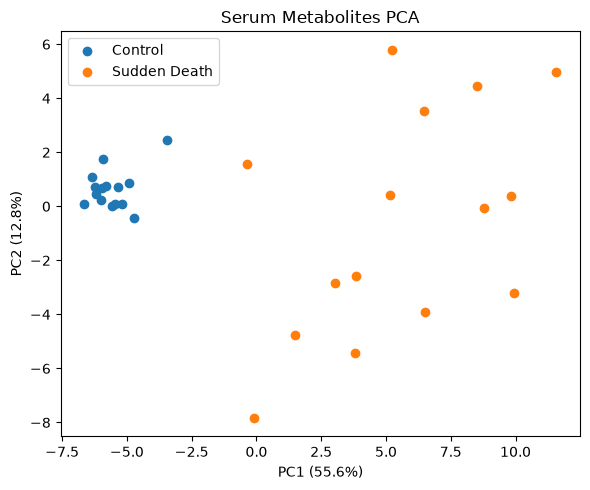

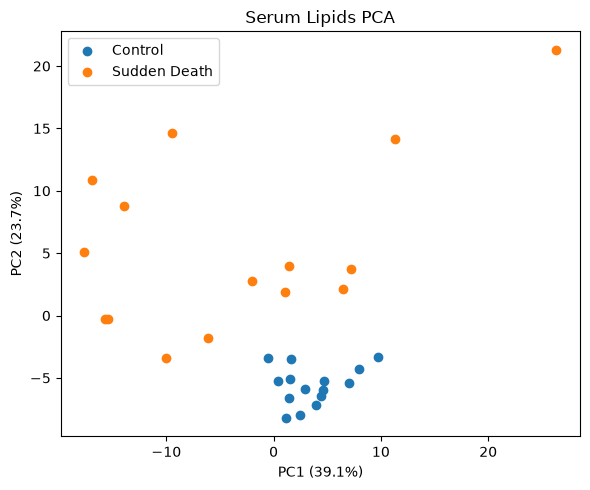

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

df = targeted_met_lipids_serum_df

# Sample groups (Excel row 4)
groups = df.iloc[2, 7:].str.strip().str.lower()
samples = groups[groups.isin(["control", "sudden death"])].index
groups = groups.loc[samples]

# Compound classes (Excel column D)
classes = df.iloc[4:, 3].astype("string").str.strip()

lipid_classes = {
    "Fatty Acids", "Ceramides", "Dihydroceramides",
    "Glycosylceramides", "Cholesterol Esters",
    "Diacylglycerols", "Phosphatidylcholines",
    "Sphingomyelins", "Triacylglycerols"
}

valid = classes.notna() & classes.ne("Class")

datasets = {
    "Metabolites": valid & ~classes.isin(lipid_classes),
    "Lipids": valid & classes.isin(lipid_classes)
}

for name, mask in datasets.items():

    # Samples as rows, compounds as columns
    X = df.loc[mask.index[mask], samples]
    X = X.apply(pd.to_numeric, errors="coerce").T

    # Remove compounds with >20% missing values
    X = X.loc[:, X.notna().mean() >= 0.8]

    # Fill missing values and remove constant compounds
    X = X.fillna(X.median())
    X = X.loc[:, X.nunique() > 1]

    # Log transformation and standardization
    X = StandardScaler().fit_transform(np.log1p(X))

    # PCA
    pca = PCA(n_components=2)
    scores = pca.fit_transform(X)

    # Plot
    plt.figure(figsize=(6, 5))

    for group in ["control", "sudden death"]:
        idx = groups == group
        plt.scatter(scores[idx, 0], scores[idx, 1],
                    label=group.title())

    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    plt.title(f"Serum {name} PCA")
    plt.legend()
    plt.tight_layout()
    plt.show()


## Targeted Metabolites and Lipids in Urine 

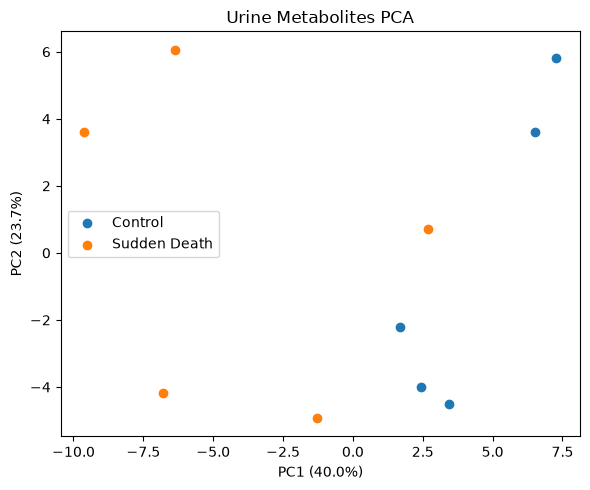

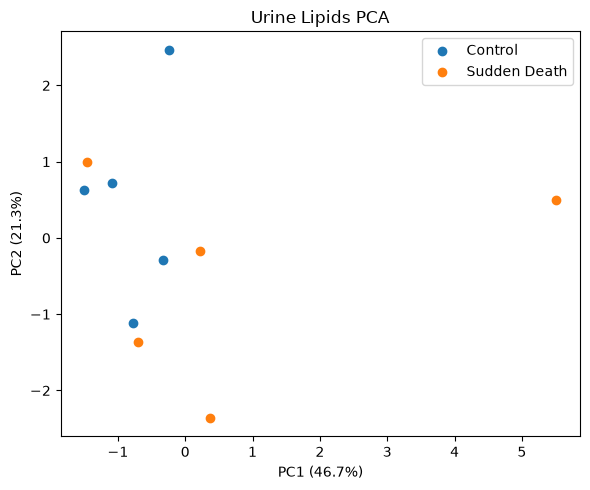

In [11]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

df = targeted_met_lipids_urine_df
reference = untargeted_lipidomics_df["Urine data"]

# Match urine sample IDs to treatment groups
sample_ids = df.iloc[0, 7:].astype(str).str.extract(r"(\d+)$")[0].astype(int)
ref_ids = pd.to_numeric(reference.iloc[0, 7:], errors="coerce")
ref_groups = reference.iloc[3, 7:].astype(str).str.strip().str.lower()

valid_ids = ref_ids.notna()
group_lookup = dict(zip(ref_ids[valid_ids].astype(int), ref_groups[valid_ids]))

groups = sample_ids.map(group_lookup)
keep = groups.isin(["control", "sudden death"])
samples = groups.index[keep]
groups = groups.loc[samples]

# Separate metabolites and lipids using compound classes
classes = df.iloc[4:, 3].astype("string").str.strip()

lipid_classes = {
    "Cholesterol Esters",
    "Phosphatidylcholines",
    "Sphingomyelins"
}

valid = classes.notna() & classes.ne("Class")

datasets = {
    "Metabolites": valid & ~classes.isin(lipid_classes),
    "Lipids": valid & classes.isin(lipid_classes)
}

for name, mask in datasets.items():

    # Samples as rows, compounds as columns
    X = df.loc[mask.index[mask], samples]
    X = X.apply(pd.to_numeric, errors="coerce").T

    # Preprocess
    X = X.loc[:, X.notna().mean() >= 0.8]
    X = X.fillna(X.median())
    X = X.loc[:, X.nunique() > 1]
    X = StandardScaler().fit_transform(np.log1p(X))

    # PCA
    pca = PCA(n_components=2)
    scores = pca.fit_transform(X)

    # Plot
    plt.figure(figsize=(6, 5))

    for group in ["control", "sudden death"]:
        idx = groups == group
        plt.scatter(scores[idx, 0], scores[idx, 1],
                    label=group.title())

    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    plt.title(f"Urine {name} PCA")
    plt.legend()
    plt.tight_layout()
    plt.show()


## Untargeted Metabolomics

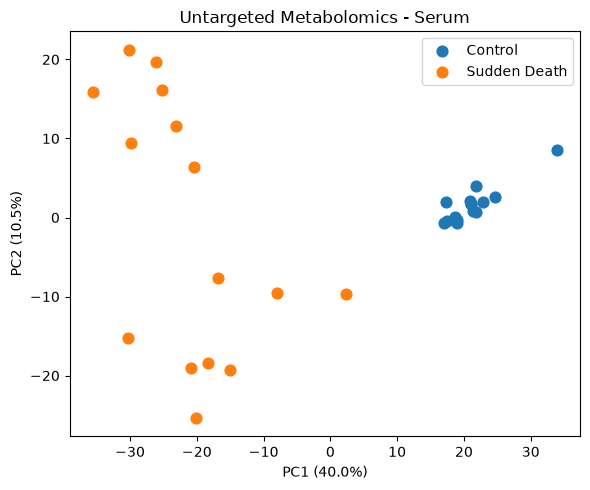

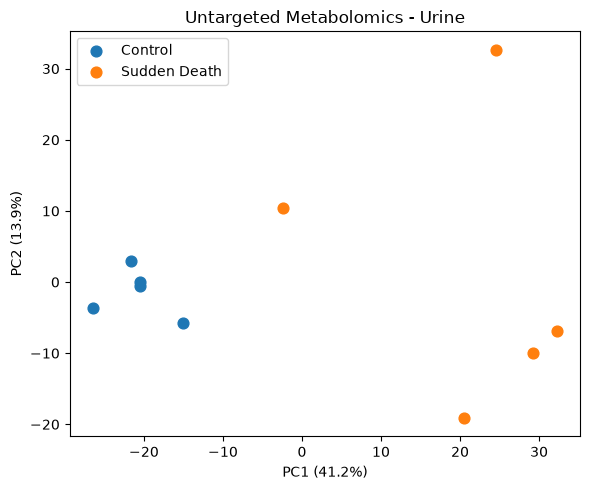

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

df = untargeted_metabolomics_df

for tissue in ["serum", "urine"]:

    # Select control and sudden death samples
    samples = [
        c for c in df.columns
        if str(c).lower().startswith(
            (f"{tissue} control", f"{tissue} sudden")
        )
    ]

    groups = np.array([
        "Control" if "control" in c.lower() else "Sudden Death"
        for c in samples
    ])

    # Samples as rows, metabolites as columns
    X = df[samples].apply(pd.to_numeric, errors="coerce").T

    # Preprocess
    X = X.mask(X <= 0)
    X = X.loc[:, X.notna().mean() >= 0.8]
    X = X.fillna(X.median())
    X = X.loc[:, X.nunique() > 1]
    X = StandardScaler().fit_transform(np.log1p(X))

    # PCA
    pca = PCA(n_components=2)
    scores = pca.fit_transform(X)

    # Plot
    plt.figure(figsize=(6, 5))

    for group in ["Control", "Sudden Death"]:
        idx = groups == group
        plt.scatter(scores[idx, 0], scores[idx, 1],
                    label=group, s=60)

    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    plt.title(f"Untargeted Metabolomics - {tissue.title()}")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [14]:
pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 21.5 MB/s  0:00:0024.5 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] 4/5 [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [15]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

df = untargeted_metabolomics_df
welch_results = {}

for tissue in ["serum", "urine"]:

    # Select control and sudden death samples
    control_cols = [c for c in df.columns if c.lower().startswith(f"{tissue} control")]
    sudden_cols = [c for c in df.columns if c.lower().startswith(f"{tissue} sudden")]

    control = df[control_cols].apply(pd.to_numeric, errors="coerce")
    sudden = df[sudden_cols].apply(pd.to_numeric, errors="coerce")

    # Treat zero and negative intensities as missing
    control = control.mask(control <= 0)
    sudden = sudden.mask(sudden <= 0)

    # Create results table
    results = df[["BinBase name", "BB id"]].copy()
    results["n_control"] = control.notna().sum(axis=1)
    results["n_sudden"] = sudden.notna().sum(axis=1)

    # Require at least 3 observations per group
    valid = (results["n_control"] >= 3) & (results["n_sudden"] >= 3)

    # Welch's t-test on log-transformed intensities
    test = ttest_ind(
        np.log1p(control.loc[valid]),
        np.log1p(sudden.loc[valid]),
        axis=1,
        equal_var=False,
        nan_policy="omit"
    )

    results["t_statistic"] = np.nan
    results["p_value"] = np.nan
    results.loc[valid, "t_statistic"] = test.statistic
    results.loc[valid, "p_value"] = test.pvalue

    # Fold change: Sudden Death / Control
    results["log2_fold_change"] = np.log2(
        sudden.mean(axis=1) / control.mean(axis=1)
    )

    # Multiple-testing correction (Benjamini-Hochberg)
    results["FDR"] = np.nan
    tested = results["p_value"].notna()
    results.loc[tested, "FDR"] = multipletests(
        results.loc[tested, "p_value"], method="fdr_bh"
    )[1]

    # Sort and save
    results = results.sort_values("p_value")
    welch_results[tissue] = results
    results.to_csv(f"{tissue}_welch_ttest.csv", index=False)

    print(f"{tissue.title()}: {tested.sum()} metabolites tested")
    print(results.head(10))


Serum: 1250 metabolites tested
             BinBase name   BB id  n_control  n_sudden  t_statistic  \
230          azelaic acid  329430         15        15    39.081679   
187          ethanolamine    3212         15        15   -26.646518   
1230               391864  391864         15        15    26.991889   
1232               400552  400552         15        15    27.594604   
1233                31764   31764         15        15    27.594604   
105   methionine sulfone     1801         15        15    19.374285   
166              glycerol      30         15        15   -15.534415   
36          suberic acid   183508         15        15    18.588384   
207       citramalic acid  592601         15        15    15.197899   
1179                20903   20903         15        15    15.358844   

           p_value  log2_fold_change           FDR  
230   9.959840e-22         -4.376407  1.244980e-18  
187   2.008302e-21          5.236053  1.255189e-18  
1230  1.570422e-19         -

## Cassie's Code

In [ ]:
import pandas as pd
import scipy.stats as stats
from statsmodels.stats.multitest import multipletests

# Exclude sample metadata
variables = df_Serum.columns.difference(["Samples", "Type"])

results = []

for variable in variables:

    control = pd.to_numeric(
        df_Serum.loc[df_Serum["Type"] == "Control", variable],
        errors="coerce"
    ).dropna()

    case = pd.to_numeric(
        df_Serum.loc[df_Serum["Type"] == "Case", variable],
        errors="coerce"
    ).dropna()

    # Welch's independent t-test
    t_stat, p_val = stats.ttest_ind(
        control,
        case,
        equal_var=False
    )

    results.append({
        "Variable": variable,
        "Control_Mean": control.mean(),
        "Case_Mean": case.mean(),
        "Mean_Difference": case.mean() - control.mean(),
        "T_Statistic": t_stat,
        "P_Value": p_val
    })

t_test_results = pd.DataFrame(results)

In [ ]:
t_test_results.to_csv(f"Documents/BrownLab/knych_mxp500/Primary_Metabolism_{Organ_Type}_T-TestResults.csv")